<p align="center"><img src="https://www.copernicuslac-chile.eu/wp-content/uploads/2024/05/logo_copernicuslac_chile.svg" alt="CopernicusLAC Chile" width="550"/></p>

# México: ODS 14 con productos CopernicusLAC y datos oficiales del SIODS
## 00 · Diagnóstico del entorno (antes del taller, 10 min)
Cada participante lo ejecuta **en su computador antes del 11 de noviembre**. Si todas las celdas terminan sin error, el notebook 01 funcionará en sala.

### Datos incluidos
- **SST y CHL:** compuestos mensuales CopernicusLAC Chile, enero–diciembre de 2024, lon −120,14 a −85,88 y lat 13,82 a 32,52.
- **ANP federales (CONANP):** 232 polígonos, 40 con superficie marina declarada (`S_MARINA`). Es la misma fuente que usa el SIODS para el 14.5.1 nacional.
- **ZEE:** Marine Regions, World EEZ v12 (compilación internacional; no es cartografía oficial INEGI ni la ZEE CONABIO del SIODS).
- **Valores oficiales:** `data/ods/referencias_oficiales_ods14.csv` (SIODS-INEGI y base ONU, consulta 13-10-2026).
- **KBA, zonificación y áreas de Protected Planet:** no incluido, pedir en la página oficial o a la guía del taller si fuese necesario(sus términos de uso restringen la redistribución); no producen ningún indicador oficial.
- **No incluidos:** costa oficial INEGI, polígonos POEM, OECM y clasificación Marine KBA.

### 1. Python y kernel
Confirme que el ejecutable corresponde al entorno registrado. Un kernel instalado no implica que esté seleccionado.

In [1]:
import sys, platform
print(sys.executable)
print(platform.python_version())

C:\Users\marin\.conda\envs\2026coplac\python.exe
3.11.17


### 2. Bibliotecas
Si alguna importación falla, active el entorno 2026coplac (`conda activate 2026coplac`) e instale environment.yml antes de avanzar.

In [2]:
import importlib, importlib.metadata
# Mismas bibliotecas que el entorno 2026coplac de los módulos terrestres (Atlas Urbano, LCLU) y de costas
modulos = ['numpy','pandas','matplotlib','xarray','netCDF4','geopandas','shapely','pyproj','pyogrio','fiona','rasterio','rioxarray','scipy','cartopy','openpyxl','ipykernel','nbclient']
for m in modulos:
    importlib.import_module(m)
    print(m, importlib.metadata.version(m))

numpy 1.26.4
pandas 2.2.3
matplotlib 3.9.4
xarray 2024.7.0
netCDF4 1.7.4
geopandas 0.14.4
shapely 2.0.7
pyproj 3.7.2
pyogrio 0.10.0
fiona 1.10.1
rasterio 1.4.3
rioxarray 0.18.2
scipy 1.14.1
cartopy 0.24.0
openpyxl 3.1.5
ipykernel 6.29.5
nbclient 0.10.4


### 3. Proyecto y rutas
La raíz del proyecto se detecta automáticamente; no hay rutas absolutas.

In [3]:
from pathlib import Path
import sys
candidatos = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
BASE = next(p for p in candidatos if (p/'environment.yml').exists() and (p/'scripts').is_dir())
sys.path.insert(0, str(BASE/'scripts'))
from herramientas import *
from IPython.display import display
FIG = BASE/'outputs/figures'; TAB = BASE/'outputs/tables'
FIG.mkdir(parents=True,exist_ok=True); TAB.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'axes.titlesize':12,'axes.labelsize':10})
print('Proyecto:', BASE)

Proyecto: C:\Users\marin\COPLAC\Taller_Mexico_ODS14_asistentes


In [4]:
for d in ['notebooks','scripts','data/sst','data/chl','data/shapes/mexico','data/ods','outputs/figures','outputs/tables']:
    print(d, (BASE/d).is_dir())

notebooks True
scripts True
data/sst True
data/chl True
data/shapes/mexico True
data/ods True
outputs/figures True
outputs/tables True


### 4. Inspección NetCDF SST y CHL
Se prueba al menos un archivo por variable. Los SST/CHL adjuntos ya están incluidos; el diagnóstico identifica capas territoriales pendientes.

In [5]:
for tipo in ['sst','chl']:
    files = sorted((BASE/'data'/tipo).rglob('*.nc'))
    print(tipo, len(files), 'archivos incluidos')
    if not files: continue
    with xr.open_dataset(files[0],decode_coords='all') as ds:
        print(ds)
        print('Fuente:',ds.attrs.get('source'), 'Institución:',ds.attrs.get('institution'))
        for v in ds.data_vars:
            print(v, ds[v].attrs.get('units'), ds[v].attrs.get('grid_mapping'))
        for c in ['time','lat','lon','latitude','longitude']:
            if c in ds: print(c, ds[c].shape, ds[c].values.min(),ds[c].values.max(),ds[c].attrs)
        print('CRS declarados:', [v for v in ds if 'grid_mapping_name' in ds[v].attrs])

sst 1 archivos incluidos
<xarray.Dataset> Size: 847MB
Dimensions:                  (time: 12, lat: 936, lon: 1714)
Coordinates:
  * time                     (time) datetime64[ns] 96B 2024-01-01 ... 2024-12-01
  * lat                      (lat) float32 4kB 13.82 13.84 13.86 ... 32.5 32.52
  * lon                      (lon) float32 7kB -120.1 -120.1 ... -85.9 -85.88
Data variables:
    analysed_sst             (time, lat, lon) float32 77MB ...
    analysis_error           (time, lat, lon) float32 77MB ...
    sea_ice_fraction         (time, lat, lon) float32 77MB ...
    mask                     (time, lat, lon) float32 77MB ...
    sses_bias                (time, lat, lon) float32 77MB ...
    sses_standard_deviation  (time, lat, lon) float32 77MB ...
    sum_sst                  (time, lat, lon) float32 77MB ...
    sum_square_sst           (time, lat, lon) float32 77MB ...
    sst_dtime                (time, lat, lon) float64 154MB ...
    wind_speed               (time, lat, lon) flo

### Revisión de los productos entregados
Los adjuntos son mensuales, enero–diciembre de 2024. SST: `analysed_sst`, K, grilla 0,02°; CHL: `chlor_a`, mg m⁻³, grilla 0,01°. Se conserva cada grilla; tamaño de celda no equivale a resolución efectiva demostrada.

**Control de metadatos:** ambos archivos tienen coordenadas lat/lon sin atributo `units`. La configuración confirma explícitamente su interpretación geográfica para estos adjuntos. No reutilice esa confirmación en productos desconocidos. Los atributos `geospatial_bounds` conservan una extensión LAC mayor que la copia recortada: use las coordenadas reales.

CHL `history` describe `exp(mean(ln(chl)))`, mientras `long_name` menciona log10-median. Se analiza la concentración almacenada sin reinterpretar el operador temporal. `source` menciona SLSTR, que no es un sensor de color del océano. Los flags `l2_flags` combinan sensores y advierten una correspondencia pendiente; no son una máscara QA validada. Estas inconsistencias deben resolverse con el productor antes de usos oficiales. SST no contiene un flag explícito de observado/reconstruido; `mask` indica agua/tierra/hielo, no procedencia.

**Revisión:** los dos NetCDF ya están en `data/sst/` y `data/chl/`. CHL `fused` describe aquí una integración multisensor atribuida a CopernicusLAC; no se sustituye la variable por un producto global. El linaje debe confirmarse con la documentación del servicio.


In [6]:
for tipo in ['sst','chl']:
    display(inventario_netcdf(BASE/'data'/tipo))

,archivo,fechas,inicio,fin,lat_min,lat_max,lon_min,lon_max,dlat_grados,dlon_grados,version,producto,variables
0,CMC_SST_2024MM_2026-10-13T153231_L4.nc,12,2024-01-01 00:00:00,2024-12-01 00:00:00,13.82,32.52,-120.139999,-85.879997,0.02,0.019997,v0.1,2024-L4_SST-monthly-GHRSST_v0.1.nc,"analysed_sst, analysis_error, sea_ice_fraction..."


,archivo,fechas,inicio,fin,lat_min,lat_max,lon_min,lon_max,dlat_grados,dlon_grados,version,producto,variables
0,CMC_CHL_2024MM_2026-10-13T153338_L4.nc,12,2024-01-01 00:00:00,2024-12-01 00:00:00,13.825,32.525,-120.145,-85.885,0.01,0.01,v1.0,2024-L4_CHL-a_monthly_v0.1,"chlor_a, l2_flags, nobs_chl, source_of_chl"


### 5. Vectores mexicanos
Revisar CRS y validez. No se asigna EPSG:4326 a una capa sin CRS. Costa puede contener líneas; ZEE y conservación deben contener polígonos.

In [7]:
capas = cargar_vectores(BASE)
for nombre,g in capas.items():
    print(nombre, len(g), g.crs, g.total_bounds, 'válidas:',g.is_valid.all())
print('Capas opcionales no incluidas (no impiden ejecutar 01):', sorted({'costa','marine_kba','oecm'}-capas.keys()))

zee 1 EPSG:4326 [-122.17910388   11.87328683  -84.64185      32.62694444] válidas: True
anp 232 EPSG:4326 [-118.63436426   11.96859932  -85.39722784   32.48332856] válidas: True
Capas opcionales no incluidas (no impiden ejecutar 01): ['costa', 'marine_kba', 'oecm']


### 6. Prueba gráfica local
No requiere descarga de costa ni mapas base.

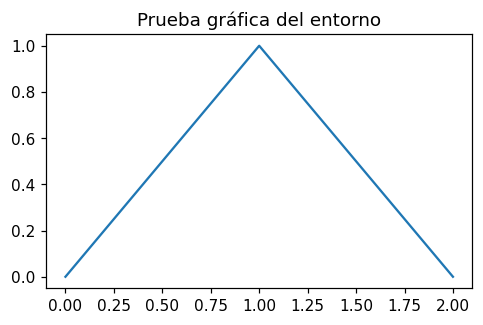

In [8]:
fig,ax=plt.subplots(figsize=(5,3));ax.plot([0,1,2],[0,1,0]);ax.set_title('Prueba gráfica del entorno');plt.show()

### Revisión y salida
¿Puede identificar tiempo, coordenadas y unidades? ¿Los archivos cubren México? ¿La variable CHL elegida pertenece al procesamiento propio? Si alguna celda falla, revise la instalación del entorno (README) antes del taller.